# Projet Airbnb, Prédiction du prix

Casimir REY et Vianney ROBERT

Le but est de prédire le logarithme du prix d'un Airbnb à partir des caractéristiques du logement. On va d'abord regarder les données, puis faire du pré-traitement, et enfin tester quelques modèles.

## 1. Chargement des données

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

train = pd.read_csv('airbnb_train.csv')
test = pd.read_csv('airbnb_test.csv')
test = test.rename(columns={'Unnamed: 0': 'id'})

print('train :', train.shape)
print('test  :', test.shape)
train.head()

train : (22234, 28)
test  : (51877, 27)


,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,...,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,zipcode,bedrooms,beds
0,5708593,4.317488,House,Private room,"{TV,""Wireless Internet"",Kitchen,""Free parking ...",3,1.0,Real Bed,flexible,False,...,NaN,33.782712,-118.134410,Island style Spa Studio,Long Beach,0,NaN,90804,0.0,2.0
1,14483613,4.007333,House,Private room,"{""Wireless Internet"",""Air conditioning"",Kitche...",4,2.0,Real Bed,strict,False,...,2017-09-17,40.705468,-73.909439,"Beautiful and Simple Room W/2 Beds, 25 Mins to...",Ridgewood,38,86.0,11385,1.0,2.0
2,10412649,7.090077,Apartment,Entire home/apt,"{TV,""Wireless Internet"",""Air conditioning"",Kit...",6,2.0,Real Bed,flexible,False,...,NaN,38.917537,-77.031651,2br/2ba luxury condo perfect for infant / toddler,U Street Corridor,0,NaN,20009,2.0,2.0
3,17954362,3.555348,House,Private room,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",1,1.0,Real Bed,flexible,True,...,2017-09-29,40.736001,-73.924248,Manhattan view from Queens. Lovely single room .,Sunnyside,19,96.0,11104,1.0,1.0
4,9969781,5.480639,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,moderate,True,...,2017-08-28,37.744896,-122.430665,Zen Captured Noe Valley House,Noe Valley,15,96.0,94131,2.0,2.0


In [39]:
miss = train.isnull().sum()
print(miss[miss > 0].sort_values(ascending=False))

host_response_rate        5475
review_scores_rating      4978
first_review              4725
last_review               4716
neighbourhood             2086
zipcode                    303
host_has_profile_pic        56
host_identity_verified      56
host_since                  56
bathrooms                   51
beds                        35
bedrooms                    26
dtype: int64


On a 22 000 lignes dans le train, 27 variables explicatives + la cible. Pas mal de valeurs manquantes sur host_response_rate, review_scores_rating et les dates de reviews. Il faudra les gérer dans le pré-traitement.

## 2. Exploration des données

On regarde 4 choses : la distribution du prix, le prix par ville, le prix par type de chambre, et les corrélations entre variables numériques.

### 2.1 Distribution de `log_price`

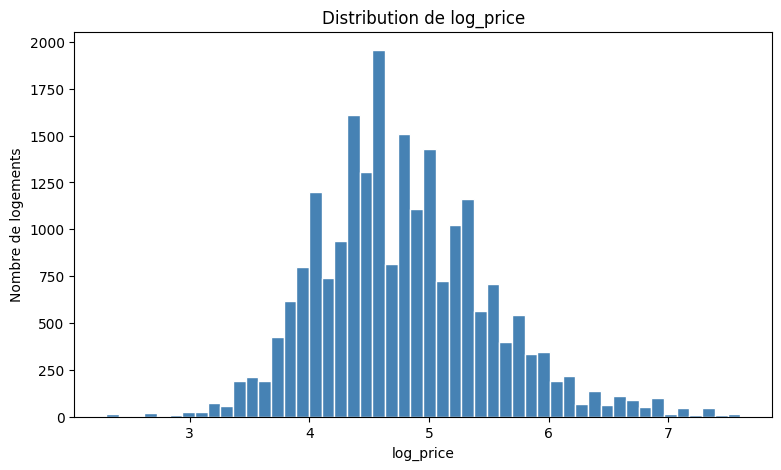

count    22234.000000
mean         4.783481
std          0.718758
min          2.302585
25%          4.317488
50%          4.700480
75%          5.220356
max          7.600402
Name: log_price, dtype: float64


In [40]:
plt.figure(figsize=(9, 5))
plt.hist(train['log_price'], bins=50, color='steelblue', edgecolor='white')
plt.title("Distribution de log_price")
plt.xlabel('log_price'); plt.ylabel('Nombre de logements')
plt.show()

print(train['log_price'].describe())

Distribution à peu près symétrique autour de 4.7 (≈ 110 $/nuit). Pas de valeurs absurdes, c'est plutôt rassurant pour la régression.

### 2.2 Prix par ville

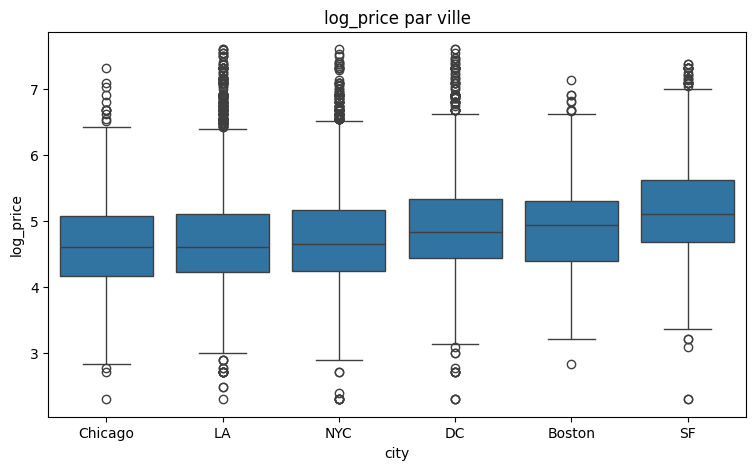

         mean  count
city                
Boston   4.88   1028
Chicago  4.65   1127
DC       4.96   1744
LA       4.71   6672
NYC      4.72   9739
SF       5.19   1924


In [41]:
plt.figure(figsize=(9, 5))
order = train.groupby('city')['log_price'].median().sort_values().index
sns.boxplot(data=train, x='city', y='log_price', order=order)
plt.title('log_price par ville')
plt.show()

print(train.groupby('city')['log_price'].agg(['mean', 'count']).round(2))

NYC et SF sont les plus chères, Chicago la moins chère. La ville influence clairement le prix, on la garde.

### 2.3 Prix par type de chambre

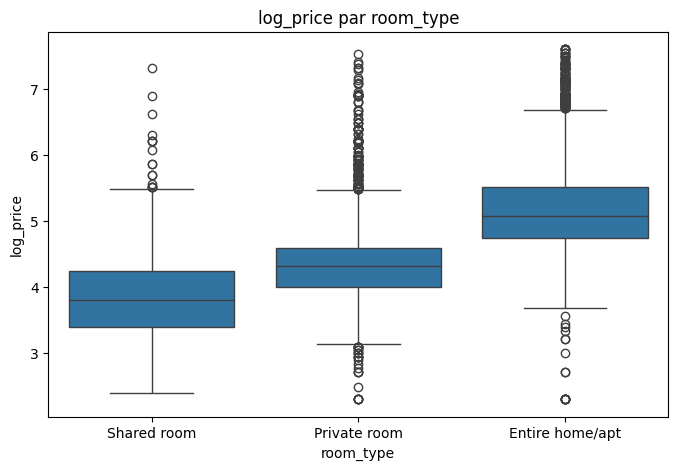

In [42]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=train, x='room_type', y='log_price',
            order=['Shared room', 'Private room', 'Entire home/apt'])
plt.title('log_price par room_type')
plt.show()

Logique : louer un appart entier coûte beaucoup plus cher qu'une chambre partagée. C'est probablement la caractéristique la plus discriminante du dataset.

### 2.4 Corrélations entre variables numériques

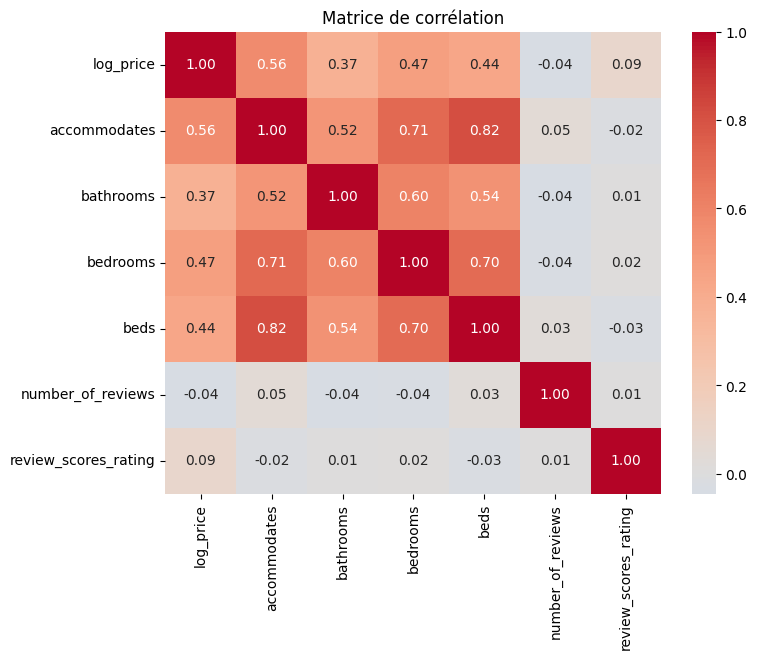

In [43]:
num_cols = ['log_price', 'accommodates', 'bathrooms', 'bedrooms', 'beds',
            'number_of_reviews', 'review_scores_rating']
corr = train[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matrice de corrélation')
plt.show()

Les variables les plus corrélées avec le prix sont accommodates (0.57), bedrooms (0.50), beds (0.45) et bathrooms (0.36). number_of_reviews est quasiment décorrélée du prix, on aurait pu la retirer mais on la garde, elle ne change rien au modèle.

## 3. Pré-traitement

On encapsule tout le pré-traitement dans une fonction pour pouvoir l'appliquer à l'identique sur le train et le test, et qu'il n'y ait pas de décalage au moment de la prédiction.

In [44]:
def preprocess(df):
    df = df.copy()

    for col in ['bathrooms', 'bedrooms', 'beds', 'review_scores_rating']:
        df[col] = df[col].fillna(df[col].median())

    df['host_response_rate'] = df['host_response_rate'].astype(str).str.replace('%', '', regex=False)
    df['host_response_rate'] = pd.to_numeric(df['host_response_rate'], errors='coerce')
    df['host_response_rate'] = df['host_response_rate'].fillna(df['host_response_rate'].median())

    for col in ['host_has_profile_pic', 'host_identity_verified', 'instant_bookable']:
        df[col] = df[col].map({'t': 1, 'f': 0}).fillna(0).astype(int)
    df['cleaning_fee'] = df['cleaning_fee'].astype(int)

    # On a essayé de faire des features binaires pour chaque amenity mais ça apportait pas grand chose,
    # On garde donc juste le nombre total.
    df['n_amenities'] = df['amenities'].astype(str).apply(lambda x: len(x.strip('{}').split(',')))

    top_props = ['Apartment', 'House', 'Condominium', 'Townhouse', 'Loft', 'Other',
                 'Guesthouse', 'Bed & Breakfast']
    df['property_type'] = df['property_type'].where(df['property_type'].isin(top_props), 'Other')

    to_drop = ['amenities', 'description', 'name', 'neighbourhood', 'zipcode',
               'first_review', 'last_review', 'host_since']
    df = df.drop(columns=to_drop)

    return df

train_p = preprocess(train)
test_p  = preprocess(test)

print('Après preprocess :')
print('train :', train_p.shape, '| test :', test_p.shape)
train_p.head()

Après preprocess :
train : (22234, 21) | test : (51877, 20)


,id,log_price,property_type,room_type,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,...,host_identity_verified,host_response_rate,instant_bookable,latitude,longitude,number_of_reviews,review_scores_rating,bedrooms,beds,n_amenities
0,5708593,4.317488,House,Private room,3,1.0,Real Bed,flexible,0,LA,...,0,100.0,1,33.782712,-118.134410,0,96.0,0.0,2.0,15
1,14483613,4.007333,House,Private room,4,2.0,Real Bed,strict,0,NYC,...,1,100.0,1,40.705468,-73.909439,38,86.0,1.0,2.0,25
2,10412649,7.090077,Apartment,Entire home/apt,6,2.0,Real Bed,flexible,0,DC,...,0,100.0,1,38.917537,-77.031651,0,96.0,2.0,2.0,20
3,17954362,3.555348,House,Private room,1,1.0,Real Bed,flexible,1,NYC,...,1,100.0,0,40.736001,-73.924248,19,96.0,1.0,1.0,30
4,9969781,5.480639,House,Entire home/apt,4,1.0,Real Bed,moderate,1,SF,...,1,100.0,0,37.744896,-122.430665,15,96.0,2.0,2.0,24


Pour les dates (first_review, host_since...), on a d'abord essayé de les convertir en nombre de jours écoulés, mais l'apport sur le score était négligeable, donc on les a supprimées pour simplifier. Idem pour description et name : faire du NLP dessus aurait été trop compliqué pour le temps imparti.

Pour les variables catégorielles restantes, on applique un one-hot encoding :

In [45]:
cat_cols = ['property_type', 'room_type', 'bed_type', 'cancellation_policy', 'city']

train_p = pd.get_dummies(train_p, columns=cat_cols, drop_first=True)
test_p  = pd.get_dummies(test_p, columns=cat_cols, drop_first=True)

features = train_p.columns.drop(['log_price', 'id'])
test_p = test_p.reindex(columns=list(features) + ['id'], fill_value=0)

X = train_p[features]
y = train_p['log_price']
X_test = test_p[features]

print('Nombre de features :', X.shape[1])

Nombre de features : 36


## 4. Modèles

On teste 5 modèles + une baseline. On split en train/val 80/20 pour comparer.

Métrique : RMSE (plus c'est bas mieux c'est) + R² (plus c'est haut mieux c'est).

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

results = []

def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f'{name:25s} | RMSE = {rmse:.4f} | R² = {r2:.4f}')
    results.append({'modele': name, 'RMSE': rmse, 'R2': r2})

### Baseline
On commence par la baseline : on prédit la moyenne du train. Si nos modèles ne font pas mieux, c'est qu'il y a un problème.

In [47]:
pred = np.full_like(y_val, y_train.mean(), dtype=float)
evaluate('Baseline (moyenne)', y_val, pred)

Baseline (moyenne)        | RMSE = 0.7159 | R² = -0.0003


### Régression linéaire


In [48]:
lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate('LinearRegression', y_val, lr.predict(X_val))

LinearRegression          | RMSE = 0.4729 | R² = 0.5634


Déjà beaucoup mieux que la baseline, on passe de 0.72 à environ 0.47.

### Ridge
Comme la régression linéaire mais régularisée. Normalement utile s'il y a beaucoup de features corrélées.

In [49]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
evaluate('Ridge', y_val, ridge.predict(X_val))

Ridge                     | RMSE = 0.4791 | R² = 0.5520


Quasi pareil que la régression linéaire. C'est attendu étant donné qu'on a pas tant de caractéristiques que ça.

### Arbre de décision
Un seul arbre, pour voir.

In [50]:
tree = DecisionTreeRegressor(max_depth=12, random_state=42)
tree.fit(X_train, y_train)
evaluate('DecisionTree (depth=12)', y_val, tree.predict(X_val))

DecisionTree (depth=12)   | RMSE = 0.4944 | R² = 0.5228


Pas terrible. On a testé différentes profondeurs (5, 12, 20, sans limite) et le résultat reste médiocre. Un seul arbre a tendance à overfitter, c'est pour ça que les méthodes d'ensemble vont être plus intéressantes.

### Random Forest
100 arbres, on agrège.

In [51]:
rf = RandomForestRegressor(n_estimators=100, max_depth=20, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
evaluate('RandomForest', y_val, rf.predict(X_val))

RandomForest              | RMSE = 0.4158 | R² = 0.6624


On passe sous les 0.42. La RF arrive à capter des effets non-linéaires que la régression linéaire ne voyait pas, par exemple les interactions entre la ville et la taille du logement.

### Gradient Boosting
Souvent ce qui marche le mieux en pratique sur des données tabulaires.

In [52]:
gb = GradientBoostingRegressor(n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)
evaluate('GradientBoosting', y_val, gb.predict(X_val))

GradientBoosting          | RMSE = 0.4006 | R² = 0.6867


C'est notre meilleur modèle (~0.40). On le garde donc pour la prédiction finale.

### Comparaison

                 modele     RMSE        R2
       GradientBoosting 0.400637  0.686684
           RandomForest 0.415846  0.662444
       LinearRegression 0.472930  0.563410
                  Ridge 0.479072  0.551997
DecisionTree (depth=12) 0.494447  0.522779
     Baseline (moyenne) 0.715868 -0.000337


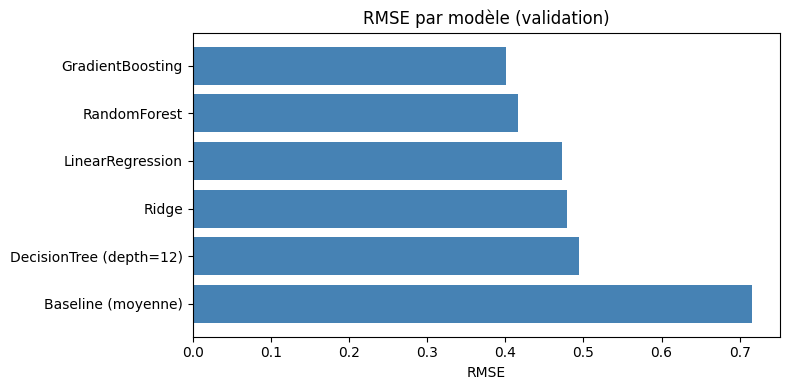

In [53]:
res_df = pd.DataFrame(results).sort_values('RMSE')
print(res_df.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.barh(res_df['modele'], res_df['RMSE'], color='steelblue')
plt.xlabel('RMSE'); plt.title('RMSE par modèle (validation)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Classement : GradientBoosting > RandomForest > Ridge ≈ LinearRegression > DecisionTree > Baseline.

Sans surprise les ensembles d'arbres gagnent. On a aussi essayé de tuner les hyperparams du GradientBoosting (learning_rate, max_depth, n_estimators) mais nous n'arrivions pas à descendre réellement plus bas.

## 5. Prédiction finale

On réentraîne le GradientBoosting sur tout le train (cette fois, sans split val), puis on prédit sur le test.

In [54]:
final_model = GradientBoostingRegressor(n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42)
final_model.fit(X, y)
preds = final_model.predict(X_test)

print('Prédictions générées :', preds.shape)
print(pd.Series(preds).describe())

Prédictions générées : (51877,)
count    51877.000000
mean         4.786076
std          0.595357
min          2.594216
25%          4.326745
50%          4.750583
75%          5.171181
max          7.766601
dtype: float64


In [55]:
submission = pd.DataFrame({'logpred': preds}, index=test['id'])
submission.index.name = ''
submission.to_csv('prediction.csv')

print('Fichier prediction.csv sauvegardé.')
print(submission.head())

Fichier prediction.csv sauvegardé.
           logpred
                  
14282777  4.905026
17029381  5.737486
7824740   4.907189
19811650  5.730602
12410741  4.510306


## Conclusion

Bilan rapide :
- Le **GradientBoosting** donne le meilleur résultat (RMSE ≈ 0.40, R² ≈ 0.69).
- Les caractéristiques les plus utiles : room_type, accommodates, bedrooms, la ville.
- Le prétraitement le plus important : convertir host_response_rate en numérique, faire le one-hot des catégorielles, compter les amenities.

Ce qu'on aurait pu pousser si on avait eu plus de temps : faire du NLP sur description, utiliser le neighbourhood avec un target encoding, et tuner les hyperparams plus sérieusement avec un GridSearchCV.